# Milestone 2: Q-learning on Taxi (requirement 1)

**Goal:** solve the pickup-and-deliver task with a tabular Q-learning agent.

Structure follows the brief: training, inference and plotting are in separate cells so each can be rerun alone.

In [1]:
import sys, json; sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, gymnasium as gym
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
from src.qlearning import train_q_learning, evaluate_q, evaluate_random
env = gym.make("Taxi-v4")

## 1. Q-learning: Q-table, hyperparameters, training loop (rewards saved)

In [2]:
HP = dict(episodes=6000, alpha=0.1, gamma=0.99, eps_start=1.0, eps_end=0.05, eps_decay=0.999, seed=0)
Q, ret, steps, ok = train_q_learning(env, **HP)
print("Q-table shape:", Q.shape, "| trained for", HP["episodes"], "episodes")

Q-table shape: (500, 6) | trained for 6000 episodes


## 2. Display the agent's progress: reward accumulated per episode against time

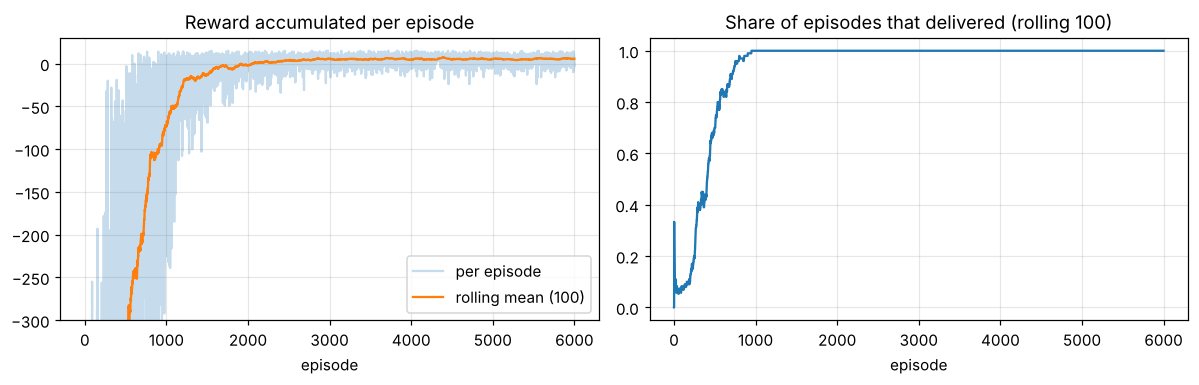

In [3]:
roll = lambda x, w=100: pd.Series(x).rolling(w, min_periods=1).mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(ret, alpha=.25, label="per episode"); ax[0].plot(roll(ret), label="rolling mean (100)")
ax[0].set(title="Reward accumulated per episode", xlabel="episode"); ax[0].set_ylim(-300, 30); ax[0].legend()
ax[1].plot(roll(ok.astype(float))); ax[1].set(title="Share of episodes that delivered (rolling 100)", xlabel="episode")
plt.tight_layout(); plt.savefig("../docs/img/m2_q_learning_curve.png"); plt.show()

## 3. Test episode: trained agent from a state of my choice, saving every frame

In [4]:
test_env = gym.make("Taxi-v4", render_mode="ansi")
test_env.reset(seed=0)
start = test_env.unwrapped.encode(3, 1, 2, 0)          # taxi (3,1), passenger at location 2, destination 0
test_env.unwrapped.s = start; s = start
frames, total, done = [test_env.render()], 0, False
while not done:
    a = int(np.argmax(Q[s])); s, r, term, trunc, _ = test_env.step(a)
    frames.append(f"action: {['south','north','east','west','pickup','dropoff'][a]}   reward: {r}\n" + test_env.render())
    total += r; done = term or trunc
print(f"episode finished in {len(frames)-1} steps, total reward {total}")

episode finished in 10 steps, total reward 11


### Function to display the saved frames

In [5]:
def show_frames(frames, every=1, limit=None):
    for i, f in enumerate(frames[:limit]):
        if i % every == 0: print(f"--- frame {i} ---\n{f}")
show_frames(frames, limit=4); print("..."); show_frames(frames[-2:])

--- frame 0 ---
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+


--- frame 1 ---
action: north   reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (North)

--- frame 2 ---
action: west   reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (West)

--- frame 3 ---
action: south   reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (South)

...
--- frame 0 ---
action: north   reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (North)

--- frame 1 ---
action: dropoff   reward: 20
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Dropoff)



## 4. Inference and evaluation on 200 unseen episodes

In [6]:
ev = evaluate_q(env, Q); base = evaluate_random(env)
print("Q-learning greedy:", ev); print("random baseline:  ", base)
json.dump(dict(q_learning=ev, random=base, test_episode=dict(steps=len(frames)-1, reward=total)), open("../results/taxi_q.json", "w"))

Q-learning greedy: {'mean_return': 8.195, 'mean_steps': 12.805, 'success_rate': 1.0}
random baseline:   {'mean_return': -772.76, 'mean_steps': 198.53, 'success_rate': 0.02}


## 5. Hyperparameter sweep (3000 episodes each, one seed per setting)

In [7]:
rows = []
for alpha in [0.05, 0.1, 0.3]:
    for gamma in [0.9, 0.99]:
        Qs, *_ = train_q_learning(env, episodes=3000, alpha=alpha, gamma=gamma, eps_decay=0.998, seed=1)
        e = evaluate_q(env, Qs); rows.append(dict(alpha=alpha, gamma=gamma, **e))
sweep = pd.DataFrame(rows).round(2); print(sweep.to_string(index=False))
sweep.to_csv("../results/taxi_q_sweep.csv", index=False)

 alpha  gamma  mean_return  mean_steps  success_rate
  0.05   0.90       -41.29       57.25          0.76
  0.05   0.99       -24.74       42.38          0.84
  0.10   0.90        -1.01       21.06          0.96
  0.10   0.99         5.14       15.55          0.98
  0.30   0.90         8.16       12.84          1.00
  0.30   0.99         8.18       12.82          1.00


## Takeaways
- A tabular Q-learning agent solves Taxi: **100% of 200 unseen episodes delivered, 12.8 steps on average, mean return 8.2**, against 2% success and a mean return of -773 for a random agent.
- The test episode from a chosen start state (taxi at row 3, column 1, passenger at location 2, destination 0) took 10 steps for a total reward of 11.
- In the sweep, learning rate mattered most: alpha=0.3 reached 100% success, while alpha=0.05 was still at 76-84% after 3,000 episodes. That is under-training, not a worse method.
- Caveat: the sweep uses one seed per setting, so treat small differences as noise.